# Đánh giá mô hình RUL và quy tắc cảnh báo sớm trên FD001

Notebook này rà soát kết quả của pipeline modeling đã lưu trong
`outputs/modeling/`. Mỗi con số được tính lại từ bảng prediction bằng chính các
hàm của package `cmapss.modeling` rồi so với artifact bằng `assert`. Notebook
không fit model và không ghi file.

Nội dung:

1. So sánh ba model ứng viên trong 5-fold GroupKFold theo engine.
2. Tính lại metric test và khoảng tin cậy bootstrap của model được chọn.
3. Phân tích sai số theo khoảng RUL thật, trên test và trên OOF train.
4. Tính lại bảng cảnh báo RUL ≤ 30 cycles từ OOF predictions.

```text
rolling_features.parquet ─┐
train_targets.parquet ────┴─> GroupKFold (OOF) ─> chọn model ─> fit toàn train ─> dự đoán test
                                    │                                                │
                                    └─> oof_predictions.parquet                      └─> final_evaluation.parquet
                                          └─> warning_events.csv                           (join RUL_FD001 sau khi dự đoán)
```

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "outputs").is_dir():
    ROOT = ROOT.parent  # notebook được mở từ thư mục notebooks/
assert (ROOT / "outputs").is_dir(), "Chạy notebook từ thư mục gốc repository"

pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})


def read_json(relative: str) -> dict:
    return json.loads((ROOT / relative).read_text(encoding="utf-8"))

from cmapss.modeling.early_warning import build_warning_events
from cmapss.modeling.metrics import bootstrap_metric_intervals, summarize_prediction_errors

MODELING = ROOT / "outputs" / "modeling"
run_info = read_json("outputs/modeling/run_info.json")
model_metrics = pd.read_csv(MODELING / "tables" / "model_metrics.csv")
fold_metrics = pd.read_csv(MODELING / "tables" / "fold_metrics.csv")
oof = pd.read_parquet(MODELING / "predictions" / "oof_predictions.parquet")
evaluation = pd.read_parquet(MODELING / "predictions" / "final_evaluation.parquet")
final_metrics = read_json("outputs/modeling/tables/final_metrics.json")
selected = run_info["selected_model"]
print("Model được chọn:", selected)
print("OOF rows:", len(oof), "| test evaluation rows:", len(evaluation))

%matplotlib inline

Model được chọn: hist_gradient_boosting
OOF rows: 53193 | test evaluation rows: 100


## 1. So sánh model trong cross-validation

Mỗi fold giữ riêng 20 train engines. Metric chọn model là `mean_engine_mae`:
tính MAE trong từng engine rồi lấy trung bình, để engine dài không chiếm trọng số
lớn hơn engine ngắn. Ô dưới đây tính lại bảng tổng hợp từ OOF predictions và so với
`model_metrics.csv`.

In [2]:
recomputed = []
for (model_name, fold), group in oof.groupby(["model_name", "fold"], sort=True):
    recomputed.append({"model_name": model_name, "fold": fold, **summarize_prediction_errors(group)})
recomputed = pd.DataFrame(recomputed)

stored = fold_metrics.set_index(["model_name", "fold"]).sort_index()
check = recomputed.set_index(["model_name", "fold"]).sort_index()
for column in ("mean_engine_mae", "rmse", "nasa_score"):
    assert np.allclose(check[column], stored[column], rtol=1e-9), column

summary = recomputed.groupby("model_name")["mean_engine_mae"].agg(["mean", "std"])
assert np.allclose(summary["mean"], model_metrics.set_index("model_name").loc[summary.index, "mean_engine_mae"])
print("Fold metrics khớp với artifact.")
summary.sort_values("mean")

Fold metrics khớp với artifact.


,mean,std
model_name,,
hist_gradient_boosting,20.2143,0.9821
ridge_alpha_1,23.9922,0.9479
median_baseline,46.9543,0.1193


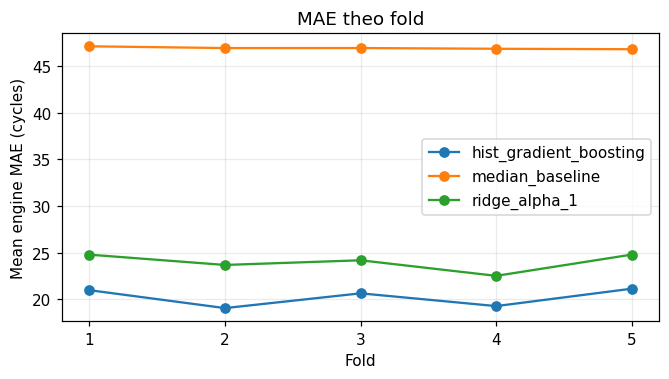

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.4))
for model_name, group in recomputed.groupby("model_name"):
    ax.plot(group["fold"], group["mean_engine_mae"], marker="o", label=model_name)
ax.set(xlabel="Fold", ylabel="Mean engine MAE (cycles)", title="MAE theo fold", xticks=range(1, 6))
ax.legend()
plt.show()

`hist_gradient_boosting` có MAE thấp nhất ở cả năm fold, nên kết luận chọn model
không phụ thuộc vào một fold riêng lẻ. Chênh lệch giữa HistGradientBoosting và
Ridge (khoảng 3.8 cycles) lớn hơn nhiều so với độ lệch chuẩn giữa các fold
(khoảng 1 cycle). Đây là quan sát mô tả trên 5 fold, không phải kiểm định thống kê.

## 2. Metric test và khoảng tin cậy bootstrap

Test FD001 có 100 engines. Mỗi engine chỉ được đánh giá tại cycle quan sát cuối,
nên `mean_window_mae` và `mean_engine_mae` bằng nhau. Khoảng tin cậy 95% được tính
lại bằng cùng seed và số lần lấy mẫu đã ghi trong `final_metrics.json`.

In [4]:
metrics = summarize_prediction_errors(evaluation)
for name, value in final_metrics["metrics"].items():
    assert np.isclose(metrics[name], value, rtol=1e-12), name

bootstrap = final_metrics["bootstrap"]
intervals = bootstrap_metric_intervals(evaluation, n_resamples=bootstrap["resamples"], seed=bootstrap["seed"])
for name, bounds in bootstrap["intervals"].items():
    assert np.isclose(intervals[name]["ci_lower"], bounds["ci_lower"]) and np.isclose(intervals[name]["ci_upper"], bounds["ci_upper"]), name

print("Metric test và khoảng tin cậy khớp với final_metrics.json.")
pd.DataFrame(intervals).T.assign(point=[metrics[name] for name in intervals])[["point", "ci_lower", "ci_upper"]]

Metric test và khoảng tin cậy khớp với final_metrics.json.


,point,ci_lower,ci_upper
mean_engine_mae,15.3490,12.7286,18.0866
rmse,20.5413,17.3442,23.5850
nasa_score,1513.2577,743.4999,2476.2743


MAE trên test (15.35 cycles) thấp hơn MAE trong cross-validation (20.21 cycles).
Hai con số không so sánh trực tiếp: CV tính trên toàn bộ trajectory từ cycle 30,
còn test chỉ tính tại điểm cuối của mỗi engine, nơi phân phối RUL thật khác.

## 3. Sai số theo khoảng RUL thật

Residual được định nghĩa là `y_pred - y_true`. Giá trị dương nghĩa là model dự đoán
RUL dài hơn thực tế; NASA score phạt nhánh này nặng hơn.

In [5]:
bins = [0, 30, 60, 90, 120, 200]
test_view = evaluation.assign(residual=evaluation["y_pred"] - evaluation["y_true"])
test_view["rul_range"] = pd.cut(test_view["y_true"], bins, include_lowest=True)
test_table = test_view.groupby("rul_range", observed=True).agg(
    engines=("engine_id", "size"),
    mae=("absolute_error", "mean"),
    mean_residual=("residual", "mean"),
    share_over=("residual", lambda values: float((values > 0).mean())),
)
test_table

,engines,mae,mean_residual,share_over
rul_range,,,,
"(-0.001, 30.0]",25,4.3830,1.4752,0.6000
"(30.0, 60.0]",14,8.7734,6.8067,0.7143
"(60.0, 90.0]",15,21.5286,13.2441,0.8000
"(90.0, 120.0]",33,21.7714,18.5918,0.9091
"(120.0, 200.0]",13,20.0859,9.6866,0.5385


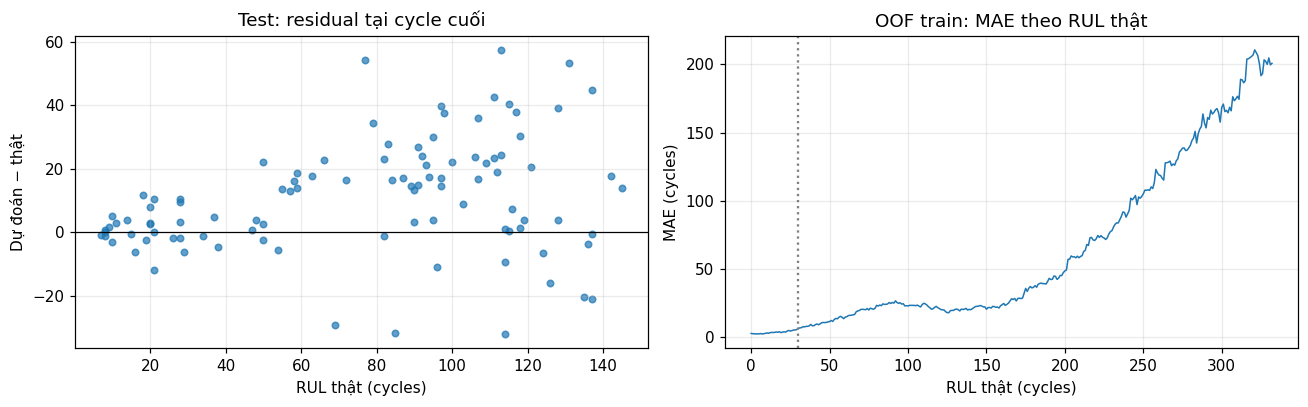

,rows,mae,mean_residual
rul_range,,,
"(-1, 30]",3100,3.6676,1.4741
"(30, 60]",3000,10.6793,5.5939
"(60, 90]",3000,20.8540,14.5156
"(90, 120]",2931,23.3368,13.7535
"(120, 150]",2460,20.5567,-0.9595
"(150, 400]",3240,49.3545,-44.5781


In [6]:
oof_selected = oof.loc[oof["model_name"].eq(selected)].assign(residual=lambda frame: frame["y_pred"] - frame["y_true"])
oof_selected["rul_range"] = pd.cut(oof_selected["y_true"], [-1, 30, 60, 90, 120, 150, 400])
oof_table = oof_selected.groupby("rul_range", observed=True).agg(
    rows=("engine_id", "size"), mae=("absolute_error", "mean"), mean_residual=("residual", "mean")
)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].scatter(test_view["y_true"], test_view["residual"], s=18, alpha=0.7)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set(xlabel="RUL thật (cycles)", ylabel="Dự đoán − thật", title="Test: residual tại cycle cuối")
curve = oof_selected.groupby("y_true")["absolute_error"].mean()
axes[1].plot(curve.index, curve.values, linewidth=1)
axes[1].axvline(30, color="gray", linestyle=":")
axes[1].set(xlabel="RUL thật (cycles)", ylabel="MAE (cycles)", title="OOF train: MAE theo RUL thật")
plt.tight_layout()
plt.show()
oof_table

Trên cả test và OOF, sai số nhỏ nhất ở vùng RUL ≤ 30 cycles (MAE test khoảng
4.4 cycles, OOF khoảng 3.7 cycles) và tăng khi RUL thật lớn. Ở đầu vòng đời, sensor
gần như chưa suy giảm nên model không đủ thông tin để phân biệt RUL 150 với RUL 250;
MAE OOF ở nhóm RUL > 150 vượt 49 cycles. Trên test, residual trung bình dương ở mọi
khoảng RUL, tức model có xu hướng dự đoán RUL dài hơn thực tế ở điểm cuối.

## 4. Quy tắc cảnh báo RUL ≤ 30 cycles

Cảnh báo đầu tiên là cycle đầu tiên có RUL dự đoán OOF không quá 30. Ô dưới đây
gọi lại `build_warning_events` và so với `warning_events.csv`. OOF cũng đã được dùng
để chọn model, nên đây là đánh giá nội bộ.

In [7]:
events, warning_summary = build_warning_events(oof, model_name=selected, rul_threshold=30)
stored_events = pd.read_csv(MODELING / "tables" / "warning_events.csv")
pd.testing.assert_frame_equal(
    events.reset_index(drop=True), stored_events[events.columns].reset_index(drop=True), check_dtype=False
)
stored_summary = read_json("outputs/modeling/tables/warning_summary.json")
for key in ("n_engines", "n_warning", "n_missed_warning", "timing_counts", "lead_time_distribution"):
    assert warning_summary[key] == stored_summary[key], key
print("Bảng cảnh báo khớp với artifact.")
pd.Series(warning_summary["timing_counts"], name="engines")

Bảng cảnh báo khớp với artifact.


before_threshold    44
at_threshold         7
after_threshold     49
at_failure           0
no_warning           0
Name: engines, dtype: int64

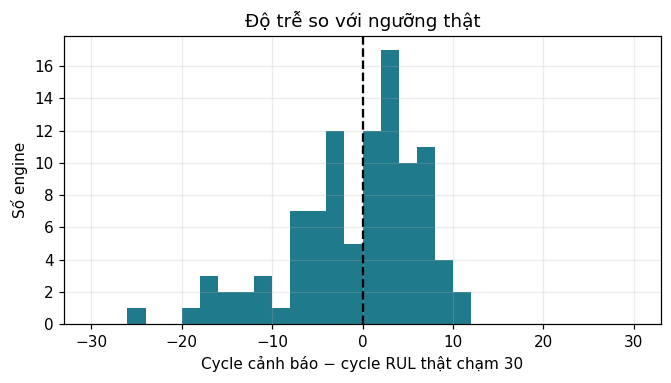

,threshold_delay_cycles,lead_time_to_failure_cycles
count,100.0000,100.0000
mean,-1.2200,31.2200
std,7.1345,7.1345
min,-25.0000,19.0000
25%,-5.0000,26.0000
50%,0.0000,30.0000
75%,4.0000,35.0000
max,11.0000,55.0000


In [8]:
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(events["threshold_delay_cycles"], bins=range(-30, 31, 2), color="#1f7a8c")
ax.axvline(0, color="black", linestyle="--")
ax.set(xlabel="Cycle cảnh báo − cycle RUL thật chạm 30", ylabel="Số engine", title="Độ trễ so với ngưỡng thật")
plt.show()
events[["threshold_delay_cycles", "lead_time_to_failure_cycles"]].describe()

## Tóm tắt

- Metric CV, metric test, khoảng tin cậy bootstrap và bảng cảnh báo đều tính lại
  khớp với artifact đã lưu.
- Model được chọn có sai số thấp ở vùng RUL nhỏ và sai số lớn ở đầu vòng đời.
- Mọi engine train đều có cảnh báo, nhưng 49 engine cảnh báo sau khi RUL thật đã
  xuống dưới 30. Ngưỡng 30 cycles là ngưỡng minh họa, chưa gắn với chi phí bảo trì.
- Kết quả chỉ áp dụng cho FD001 với protocol đã nêu.